# Détection de fraude sur des transactions mobile money

Données : PaySim (Kaggle). C'est un simulateur construit à partir d'un mois de transactions réelles d'un service de mobile money en Afrique. Il y a 6,3 millions de transactions sur 744 heures (31 jours).

Ma question de départ : si une équipe antifraude ne peut contrôler qu'un nombre limité de transactions par jour, lesquelles faut-il regarder en premier ?

Le fichier n'est pas dans le repo (493 Mo). Pour relancer le notebook, il faut le télécharger sur Kaggle et le mettre dans `data/paysim.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import average_precision_score, precision_recall_curve

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLEU, ROUGE, GRIS = "#2b5d8a", "#c0392b", "#9aa5b1"

In [2]:
types = {"step": "int16", "type": "category", "amount": "float64",
         "oldbalanceOrg": "float64", "newbalanceOrig": "float64",
         "oldbalanceDest": "float64", "newbalanceDest": "float64",
         "isFraud": "int8", "isFlaggedFraud": "int8"}
df = pd.read_csv("data/paysim.csv", usecols=list(types), dtype=types)
df["heure"] = df["step"] % 24
df["jour"] = df["step"] // 24
print(df.shape)
print(f"Taux de fraude global : {df.isFraud.mean():.4%} ({df.isFraud.sum()} fraudes)")

(6362620, 11)
Taux de fraude global : 0.1291% (8213 fraudes)


## 1. Où se trouve la fraude ?

In [3]:
par_type = df.groupby("type", observed=True)["isFraud"].agg(transactions="count", fraudes="sum")
par_type["taux"] = par_type.fraudes / par_type.transactions
par_type.sort_values("transactions", ascending=False)

,transactions,fraudes,taux
type,,,
CASH_OUT,2237500,4116,0.001840
PAYMENT,2151495,0,0.000000
CASH_IN,1399284,0,0.000000
TRANSFER,532909,4097,0.007688
DEBIT,41432,0,0.000000


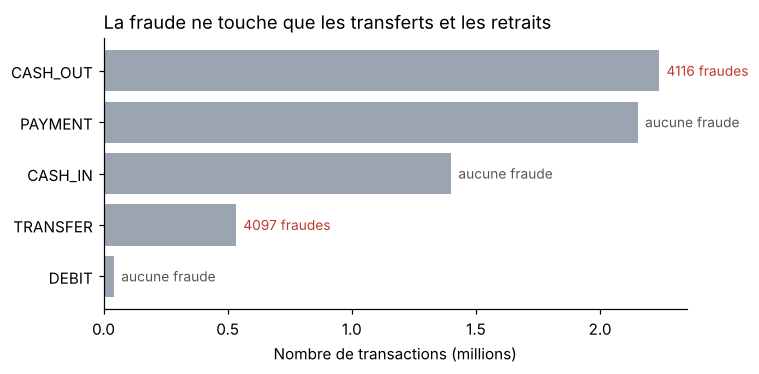

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
t = par_type.sort_values("transactions")
ax.barh(t.index.astype(str), t.transactions / 1e6, color=GRIS, label="transactions (millions)")
for i, (n, f) in enumerate(zip(t.transactions, t.fraudes)):
    ax.text(n / 1e6 + 0.03, i, f"{f} fraudes" if f else "aucune fraude", va="center", fontsize=9,
            color=ROUGE if f else "#555")
ax.set_xlabel("Nombre de transactions (millions)")
ax.set_title("La fraude ne touche que les transferts et les retraits", loc="left")
plt.tight_layout(); plt.savefig("figures/01_fraude_par_type.png"); plt.show()

In [5]:
fraudes = df[df.isFraud == 1]
tc = df[df.type.isin(["TRANSFER", "CASH_OUT"])]
normales = tc[tc.isFraud == 0]
def vide(s):
    return ((s.oldbalanceOrg > 0) & (s.amount >= s.oldbalanceOrg)).mean()
print(f"Fraudes qui vident un compte non vide : {vide(fraudes):.1%}")
print(f"Transferts/retraits normaux qui vident un compte non vide : {vide(normales):.1%}")
print(f"Opérations lancées depuis un compte à solde nul : fraudes {(fraudes.oldbalanceOrg == 0).mean():.1%}, "
      f"normales {(normales.oldbalanceOrg == 0).mean():.1%}")
print(f"Montant médian d'une fraude : {fraudes.amount.median():,.0f}")
print(f"Montant médian d'un transfert/retrait normal : {normales.amount.median():,.0f}")

Fraudes qui vident un compte non vide : 97.7%
Transferts/retraits normaux qui vident un compte non vide : 42.7%
Opérations lancées depuis un compte à solde nul : fraudes 0.5%, normales 47.4%
Montant médian d'une fraude : 441,423
Montant médian d'un transfert/retrait normal : 171,034


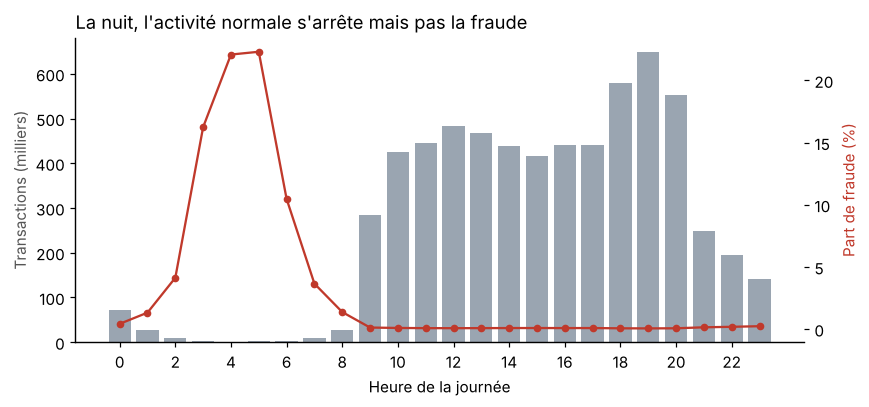

,part des transactions,part des fraudes
0h à 7h,2.0,32.7
8h à 23h,98.0,67.3


In [6]:
h = df.groupby("heure").agg(transactions=("isFraud", "size"), fraudes=("isFraud", "sum"))
h["taux"] = h.fraudes / h.transactions

fig, ax1 = plt.subplots(figsize=(8, 3.8))
ax1.bar(h.index, h.transactions / 1e3, color=GRIS)
ax1.set_ylabel("Transactions (milliers)", color="#555")
ax1.set_xlabel("Heure de la journée")
ax2 = ax1.twinx()
ax2.plot(h.index, h.taux * 100, color=ROUGE, marker="o", ms=4)
ax2.set_ylabel("Part de fraude (%)", color=ROUGE)
ax2.spines["top"].set_visible(False)
ax1.set_xticks(range(0, 24, 2))
ax1.set_title("La nuit, l'activité normale s'arrête mais pas la fraude", loc="left")
plt.tight_layout(); plt.savefig("figures/02_fraude_par_heure.png"); plt.show()
nuit = df.heure.between(0, 7)
pd.DataFrame({"part des transactions": [nuit.mean(), (~nuit).mean()],
              "part des fraudes": [nuit[df.isFraud == 1].mean(), (~nuit)[df.isFraud == 1].mean()]},
             index=["0h à 7h", "8h à 23h"]).mul(100).round(1)

## 2. Ce que fait la règle actuelle

Le jeu de données contient une colonne `isFlaggedFraud`. D'après la description du dataset, le système bloque les transferts de plus de 200 000. Je regarde ce que cette règle rattrape.

In [7]:
pd.crosstab(df.isFraud, df.isFlaggedFraud, rownames=["fraude réelle"], colnames=["bloquée par la règle"])

bloquée par la règle,0,1
fraude réelle,,
0,6354407,0
1,8197,16


La règle ne bloque que 16 opérations sur tout le mois, et ce sont bien des fraudes, mais il en reste 8 197 qui passent. En pratique elle ne s'applique presque jamais.

Pour être juste avec l'approche par règle, je teste plus loin une version plus large : signaler tous les transferts de plus de 200 000.

## 3. Préparer les données pour le modèle

Je garde seulement les transferts et les retraits, puisque les autres types n'ont aucune fraude.

Pour le découpage, je ne mélange pas les transactions au hasard. J'entraîne sur le passé et je teste sur le futur, comme ça se passerait en vrai :

- apprentissage : heures 1 à 250
- validation (pour arrêter l'entraînement au bon moment) : heures 251 à 300
- test : heures 301 à 400

Je m'arrête à l'heure 400 parce qu'après, le simulateur génère très peu de transactions normales alors que la fraude continue au même rythme. Le taux de fraude passe de 0,2 % à plus de 1,5 %, ce qui n'est pas réaliste.

In [8]:
print(tc.groupby(tc.step > 400)["isFraud"].agg(["size", "sum", "mean"]))

          size   sum     mean
step                         
False  2529536  4477  0.00177
True    240873  3736  0.01551


In [9]:
d = tc[tc.step <= 400].copy()
d["log_montant"] = np.log1p(d.amount)
d["log_solde_avant"] = np.log1p(d.oldbalanceOrg)
d["transfert"] = (d.type == "TRANSFER").astype(int)
d["vide_le_compte"] = ((d.oldbalanceOrg > 0) & (d.amount >= d.oldbalanceOrg)).astype(int)
d["solde_nul"] = (d.oldbalanceOrg == 0).astype(int)
d["part_du_solde"] = d.amount / (d.oldbalanceOrg + 1)
d["nuit"] = d.heure.between(0, 7).astype(int)

# écarts comptables : le solde après ne correspond pas au solde avant +/- le montant
d["ecart_emetteur"] = d.oldbalanceOrg - d.amount - d.newbalanceOrig
d["ecart_destinataire"] = d.oldbalanceDest + d.amount - d.newbalanceDest

train = d[d.step <= 250]
valid = d[(d.step > 250) & (d.step <= 300)]
test = d[d.step > 300]
for nom, s in [("train", train), ("valid", valid), ("test", test)]:
    print(f"{nom:5} {len(s):>9,} transactions  {s.isFraud.sum():>5} fraudes")

train 1,422,759 transactions   2841 fraudes
valid   357,785 transactions    560 fraudes
test    748,992 transactions   1076 fraudes


## 4. Premier essai avec toutes les variables

In [10]:
def entrainer_lgb(cols):
    m = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.03, num_leaves=31,
                           min_child_samples=200, subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.8, reg_lambda=5, verbose=-1, random_state=42)
    m.fit(train[cols], train.isFraud, eval_X=(valid[cols],), eval_y=(valid.isFraud,),
          eval_metric="average_precision", callbacks=[lgb.early_stopping(100, verbose=False)])
    return m

toutes = ["log_montant", "transfert", "heure", "log_solde_avant", "newbalanceOrig",
          "oldbalanceDest", "newbalanceDest", "ecart_emetteur", "ecart_destinataire",
          "vide_le_compte", "solde_nul", "part_du_solde"]
m_toutes = entrainer_lgb(toutes)
p_toutes = m_toutes.predict_proba(test[toutes])[:, 1]
print(f"Précision moyenne (AP) sur le test : {average_precision_score(test.isFraud, p_toutes):.4f}")
pd.Series(m_toutes.booster_.feature_importance("gain"), index=toutes).sort_values(ascending=False).round(0)

Précision moyenne (AP) sur le test : 0.9999


newbalanceOrig        121624.0
oldbalanceDest         80150.0
newbalanceDest         51044.0
part_du_solde          28967.0
ecart_emetteur         14069.0
log_solde_avant        12252.0
transfert               4959.0
ecart_destinataire       102.0
heure                      0.0
log_montant                0.0
vide_le_compte             0.0
solde_nul                  0.0
dtype: float64

Le score est presque parfait. Ça m'a paru trop beau, donc j'ai regardé d'où ça venait.

Les variables sur les soldes après la transaction (côté émetteur et côté destinataire) font presque tout le travail. Dans PaySim, ces soldes ne sont pas mis à jour de la même façon pour les fraudes et pour les opérations normales. Le modèle apprend donc un défaut du simulateur, pas un comportement de fraudeur. Dans une vraie banque ces informations ne seraient pas disponibles au moment de valider le paiement, ou elles n'auraient pas ce défaut.

Je refais donc le modèle avec seulement ce qu'on connaît au moment où le client lance l'opération.

## 5. Modèle avec les informations disponibles au moment de la transaction

In [11]:
dispo = ["log_montant", "transfert", "heure", "nuit", "log_solde_avant", "vide_le_compte", "solde_nul", "part_du_solde"]

reglog = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
reglog.fit(train[dispo], train.isFraud)
p_reglog = reglog.predict_proba(test[dispo])[:, 1]

m_dispo = entrainer_lgb(dispo)
p_lgb = m_dispo.predict_proba(test[dispo])[:, 1]

regle = ((test.type == "TRANSFER") & (test.amount > 200_000)).astype(int)

print(f"Régression logistique AP : {average_precision_score(test.isFraud, p_reglog):.3f}")
print(f"LightGBM AP              : {average_precision_score(test.isFraud, p_lgb):.3f}")
print(f"Règle 'transfert > 200k' : rappel {regle[test.isFraud == 1].mean():.1%}, "
      f"précision {test.isFraud[regle == 1].mean():.1%}")
pd.Series(m_dispo.booster_.feature_importance("gain"), index=dispo).sort_values(ascending=False).round(0)

Régression logistique AP : 0.053
LightGBM AP              : 0.974
Règle 'transfert > 200k' : rappel 34.0%, précision 0.3%


part_du_solde      427477.0
vide_le_compte      51858.0
log_solde_avant     22152.0
log_montant         17263.0
heure               14433.0
transfert            8553.0
nuit                  753.0
solde_nul             214.0
dtype: float64

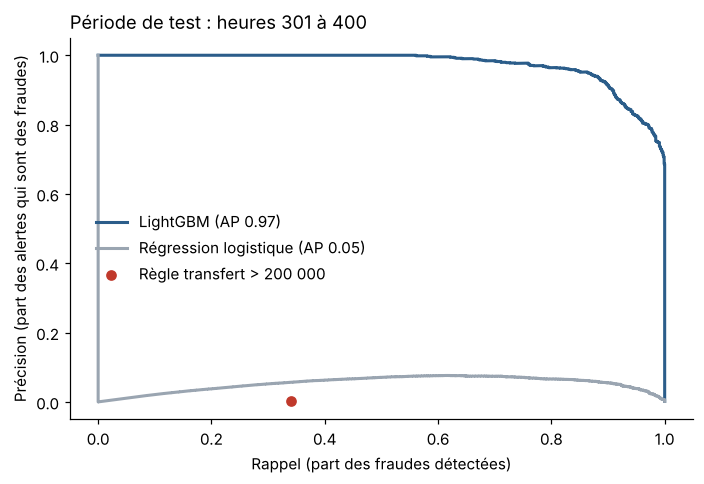

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for p, nom, c in [(p_lgb, "LightGBM", BLEU), (p_reglog, "Régression logistique", GRIS)]:
    pr, rc, _ = precision_recall_curve(test.isFraud, p)
    ax.plot(rc, pr, color=c, lw=2, label=f"{nom} (AP {average_precision_score(test.isFraud, p):.2f})")
ax.scatter(regle[test.isFraud == 1].mean(), test.isFraud[regle == 1].mean(), color=ROUGE, zorder=3,
           label="Règle transfert > 200 000")
ax.set_xlabel("Rappel (part des fraudes détectées)")
ax.set_ylabel("Précision (part des alertes qui sont des fraudes)")
ax.set_title("Période de test : heures 301 à 400", loc="left")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(0.02, 0.45))
plt.tight_layout(); plt.savefig("figures/03_precision_rappel.png"); plt.show()

## 6. Combien de contrôles par jour ?

Un score ne sert à rien si l'équipe ne peut pas tout contrôler. Je simule une équipe qui contrôle un nombre fixe de transactions par jour, en prenant celles avec le score le plus haut.

Je compare deux façons de trier les alertes :

- par probabilité de fraude
- par perte attendue, c'est à dire probabilité x montant. L'idée est de regarder d'abord les fraudes qui coûtent le plus cher.

In [13]:
nb_jours = test.step.nunique() / 24
y = test.isFraud.values
montant = test.amount.values
perte_totale = (montant * y).sum()

def capture(score, alertes_par_jour):
    n = int(alertes_par_jour * nb_jours)
    top = np.argsort(-score)[:n]
    return y[top].sum() / y.sum(), (montant[top] * y[top]).sum() / perte_totale, y[top].mean()

print(f"Transactions par jour dans le test : {len(test) / nb_jours:,.0f}")
print(f"Fraudes par jour dans le test : {y.sum() / nb_jours:.0f}")
print(f"Alertes par jour avec la règle large : {regle.sum() / nb_jours:,.0f}")

lignes = []
for k in [25, 50, 100, 200, 300]:
    r1, m1, p1 = capture(p_lgb, k)
    r2, m2, p2 = capture(p_lgb * montant, k)
    lignes.append({"contrôles/jour": k,
                   "fraudes détectées (tri proba)": r1, "montant récupéré (tri proba)": m1,
                   "fraudes détectées (tri perte)": r2, "montant récupéré (tri perte)": m2,
                   "précision (tri perte)": p2})
capacite = pd.DataFrame(lignes).set_index("contrôles/jour")
(capacite * 100).round(1)

Transactions par jour dans le test : 179,758
Fraudes par jour dans le test : 258
Alertes par jour avec la règle large : 28,588


,fraudes détectées (tri proba),montant récupéré (tri proba),fraudes détectées (tri perte),montant récupéré (tri perte),précision (tri perte)
contrôles/jour,,,,,
25,9.7,26.1,9.7,50.7,100.0
50,19.3,44.9,19.3,74.3,100.0
100,38.7,78.5,38.6,90.7,99.8
200,75.7,85.7,72.4,98.6,93.5
300,95.4,99.6,91.4,99.9,78.6


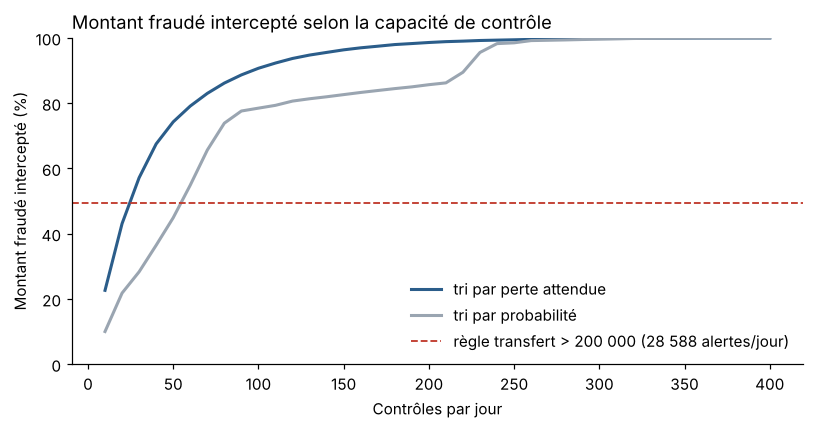

In [14]:
ks = np.arange(10, 401, 10)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(ks, [capture(p_lgb * montant, k)[1] * 100 for k in ks], color=BLEU, lw=2, label="tri par perte attendue")
ax.plot(ks, [capture(p_lgb, k)[1] * 100 for k in ks], color=GRIS, lw=2, label="tri par probabilité")
alertes_regle = regle.sum() / nb_jours
ax.axhline(regle.values @ (montant * y) / perte_totale * 100, color=ROUGE, ls="--", lw=1.2,
           label=f"règle transfert > 200 000 ({alertes_regle:,.0f} alertes/jour)".replace(",", " "))
ax.set_xlabel("Contrôles par jour")
ax.set_ylabel("Montant fraudé intercepté (%)")
ax.set_ylim(0, 100)
ax.set_title("Montant fraudé intercepté selon la capacité de contrôle", loc="left")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig("figures/04_capacite_controle.png"); plt.show()

## 7. Ce que je retiens

Le profil de la fraude est très net dans ces données : un transfert qui vide le compte, souvent la nuit, suivi d'un retrait. La part du solde envoyée est la variable la plus utile du modèle.

La règle « transfert de plus de 200 000 » n'est pas adaptée. Dans sa version réelle elle ne bloque presque rien, et dans sa version large elle génère des centaines d'alertes pour très peu de fraudes.

Avec le modèle, une équipe qui fait 100 contrôles par jour intercepte environ 90 % du montant fraudé si elle trie les alertes par perte attendue, contre environ 78 % si elle trie par probabilité. Le tri compte autant que le modèle.

Limite importante : ce sont des données simulées. Les fraudeurs de PaySim suivent tous le même scénario, ce qui explique des scores aussi élevés. Sur des vraies données il faudrait s'attendre à beaucoup moins, et ajouter l'historique du client (fréquence habituelle, montants habituels, nouveaux bénéficiaires).